# NSGA-II con codificación directa — Maximización de revenue

NSGA-II propio (Deb et al., 2002) sobre el mismo encoding y los mismos
operadores del GA del cuaderno `6.0-GA_Direct_Encoding.ipynb`: cada individuo
codifica, por servicio, **si se planifica** (`b`) y los **deltas en minutos**
(`δ`) respecto de los horarios solicitados por las RUs. El algoritmo sustituye
el torneo k-ario y el elitismo del GA por sus tres piezas características —
*fast non-dominated sort*, distancia de hacinamiento y selección ambiental
μ+λ — manteniendo el cruce por bloques y la mutación gaussiana entera.

Con el objetivo único de **revenue penalizado** (el mismo fitness del GA) el
frente de Pareto colapsa y NSGA-II degenera en un GA elitista por rangos: es
la comparación de manzanas con manzanas que buscamos, ejercitando a la vez la
maquinaria lista para un segundo objetivo (p. ej. equidad).

La instancia es la de siempre (`0.0-Synthetic_Data_Generator.ipynb`): 50
servicios Madrid → Barcelona de un mismo día. La lógica vive en `craft.ga`
(`nsga2.py`); este cuaderno solo compone la ejecución y la comparativa.

## 0. Librerías

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from craft.ga import GA, NSGA2, load_problem
from craft.ga.plotting import (
    plot_evolution,
    plot_genome_filmstrip,
    plot_timetable,
    plot_timetable_filmstrip,
)

DATA = Path('../data/synthetic')


def hhmm(minutes):
    minutes = int(minutes)
    return f'{minutes // 60:02d}:{minutes % 60:02d}'

## 1. La instancia

`load_problem` construye el problema a partir de los dos archivos del
cuaderno 0.0 (el headway y el margen del IM se leen de sus metadatos). El
genoma tiene un bloque `[b, δ…]` por servicio; el baseline de referencia es
la heurística del paper publicado (resolver los conflictos sobre los
horarios solicitados soltando el servicio de menor canon).

In [2]:
problem = load_problem(DATA / 'timetable.yaml', DATA / 'revenue.yaml')

n_conflicts = int(np.triu(problem.conflict_matrix(problem.requested_schedules), 1).sum())
greedy_n, greedy_revenue = problem.greedy_baseline()
canon_total = sum(p['canon'] for p in problem.revenue_behavior.values())

print(f'servicios solicitados  : {problem.n_services}')
print(f'tamaño del genoma      : {problem.genome_size} genes = '
      f'{problem.n_services} bits b + {problem.genome_size - problem.n_services} deltas')
print(f'safe_headway           : {problem.safe_headway} min | margen del IM: ±{problem.im_mod_margin} min')
print(f'canon total            : {canon_total:.2f}')
print(f'conflictos solicitados : {n_conflicts} pares de servicios')
print(f'baseline greedy        : {greedy_n} servicios, revenue = {greedy_revenue:.2f}')

servicios solicitados  : 50
tamaño del genoma      : 217 genes = 50 bits b + 167 deltas
safe_headway           : 10 min | margen del IM: ±60 min
canon total            : 2028.77
conflictos solicitados : 103 pares de servicios
baseline greedy        : ['00003', '00004', '00009', '00010', '00013', '00015', '00017', '00030', '00032', '00034', '00035', '00036', '00038', '00040', '00044', '00047', '00048'] servicios, revenue = 729.53


## 2. Optimización con NSGA-II

Cada generación evalúa solo a la descendencia (los padres conservan sus
objetivos), fusiona ambas poblaciones (μ+λ) y sobreviven los mejores frentes
hasta agotar el presupuesto; el frente que lo cruza se trunca por distancia
de hacinamiento. Los torneos binarios usan la comparación apiñada: gana el
mejor rango y, en caso de empate, el individuo menos apiñado.

Los operadores de variación y sus hiperparámetros son los del GA
(`pc = 0.9`, `pm = 0.05`, `σ = 2`, `pr = 0.1`); el objetivo es el fitness
penalizado del problema, sin maquinaria de restricciones adicional.

In [3]:
nsga = NSGA2(problem, pop_size=50)
history_nsga = nsga.optimize(epoch=150, seed=42, verbose=False)

print(f'mejor fitness         : {nsga.best_fitness:.2f}')
print(f'servicios planificados: {history_nsga["Planned"].iloc[-1]} de {problem.n_services}')
print(f'conflictos finales    : {history_nsga["Conflicts"].iloc[-1]}')
print(f'tiempo de ejecución   : {nsga.execution_time:.1f} s')

mejor fitness         : 800.03
servicios planificados: 19 de 50
conflictos finales    : 0
tiempo de ejecución   : 7.7 s


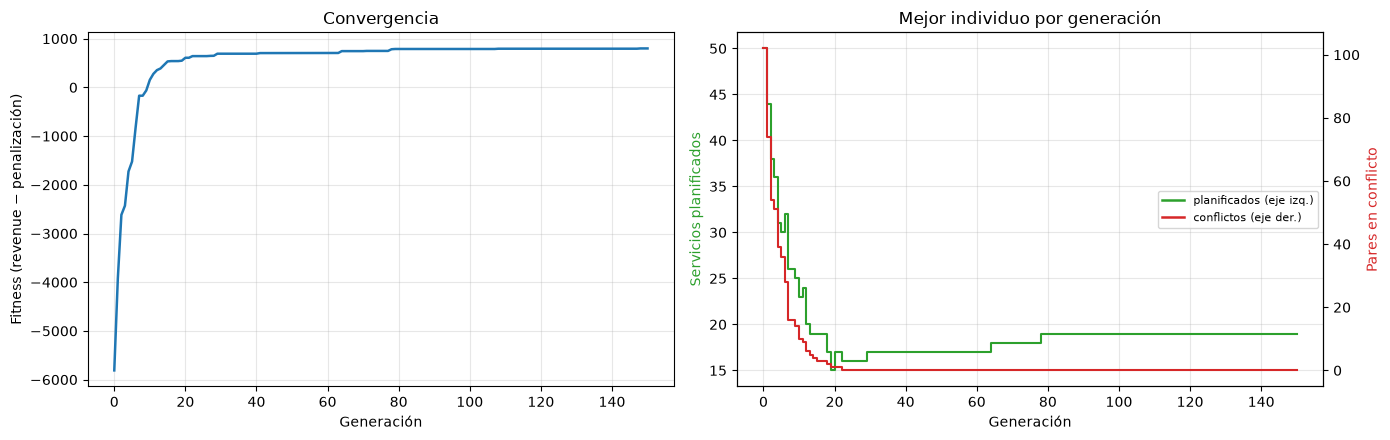

In [4]:
fig = plot_evolution(history_nsga)
plt.show()

### El frente final

Con un único objetivo el *fast non-dominated sort* produce frentes de un
individuo (salvo empates exactos de fitness), así que `pareto_genomes` se
reduce al mejor individuo de la población final. La columna vertebral
multiobjetivo queda, sin embargo, ejercitada y lista para crecer.

In [5]:
pareto_df = pd.DataFrame(nsga.pareto_values, columns=['fitness'])
print(f'miembros del frente final: {len(pareto_df)}')
pareto_df

miembros del frente final: 1


,fitness
0,800.028239


## 3. Evolución de los individuos

Como el GA, NSGA-II guarda el mejor individuo de cada generación
(`best_genomes`), con color por servicio consistente entre paneles: se ve
qué servicios se podan (pasan a gris), cuáles se mantienen sin cambio y
cuáles viajan desplazados (línea discontinua del mismo color bajo la
continua).

/var/folders/dc/fy76phnd5ljbdtj9v4jgnyjh0000gp/T/ipykernel_7550/920469524.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


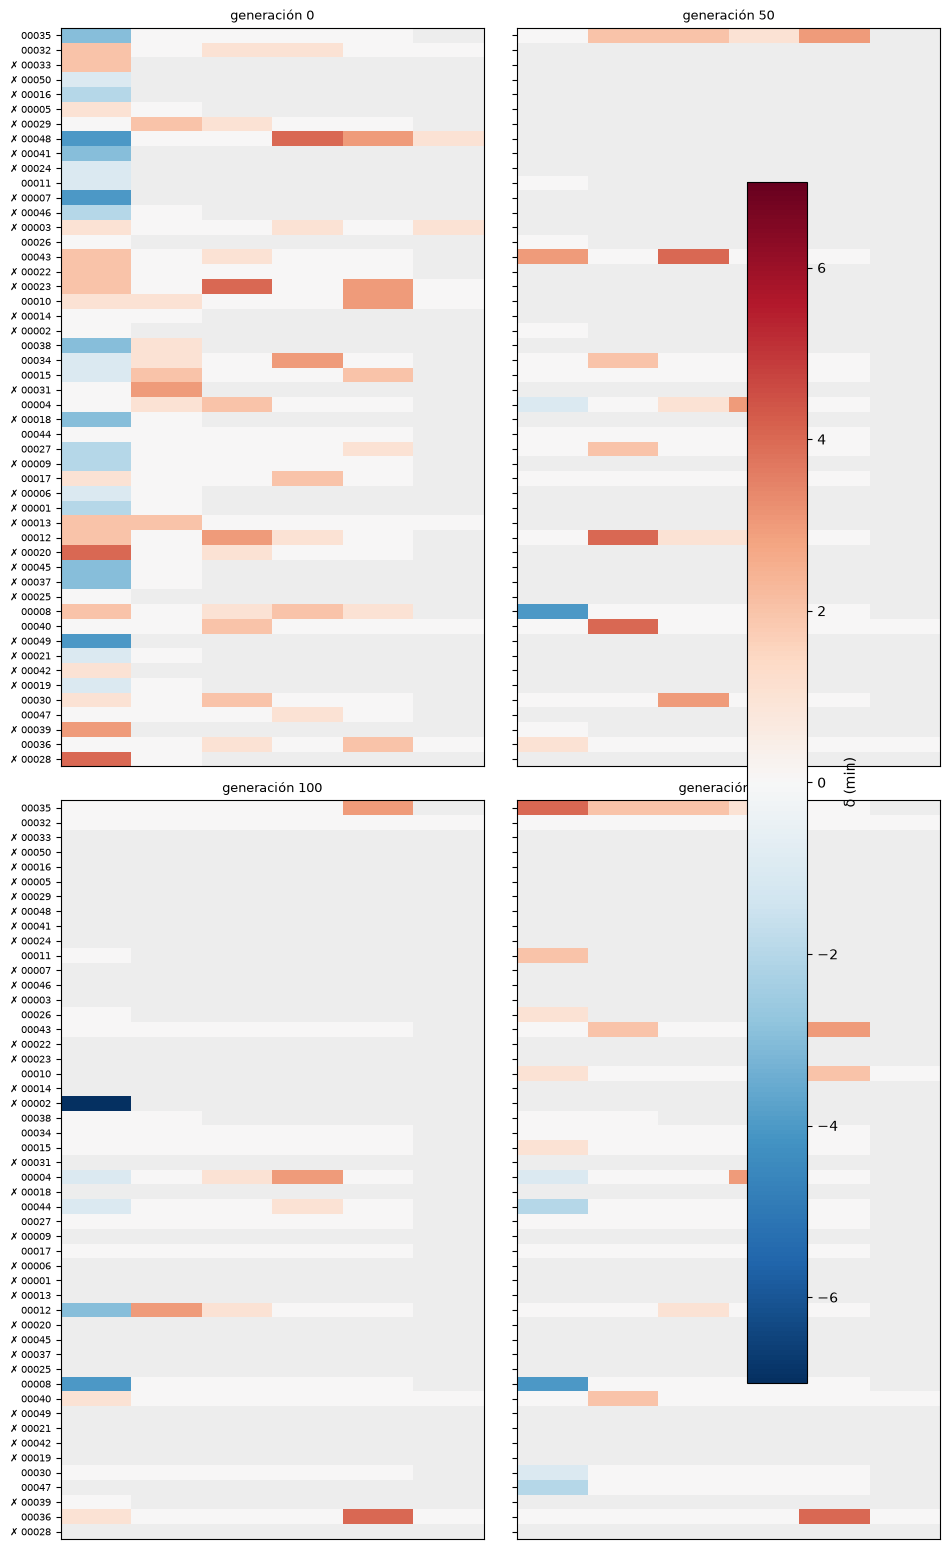

In [6]:
steps = [0, 50, 100, 150]
genomes = nsga.best_genomes[steps]
titles = [f'generación {g}' for g in steps]

fig = plot_genome_filmstrip(problem, genomes, titles)
fig.tight_layout()
plt.show()

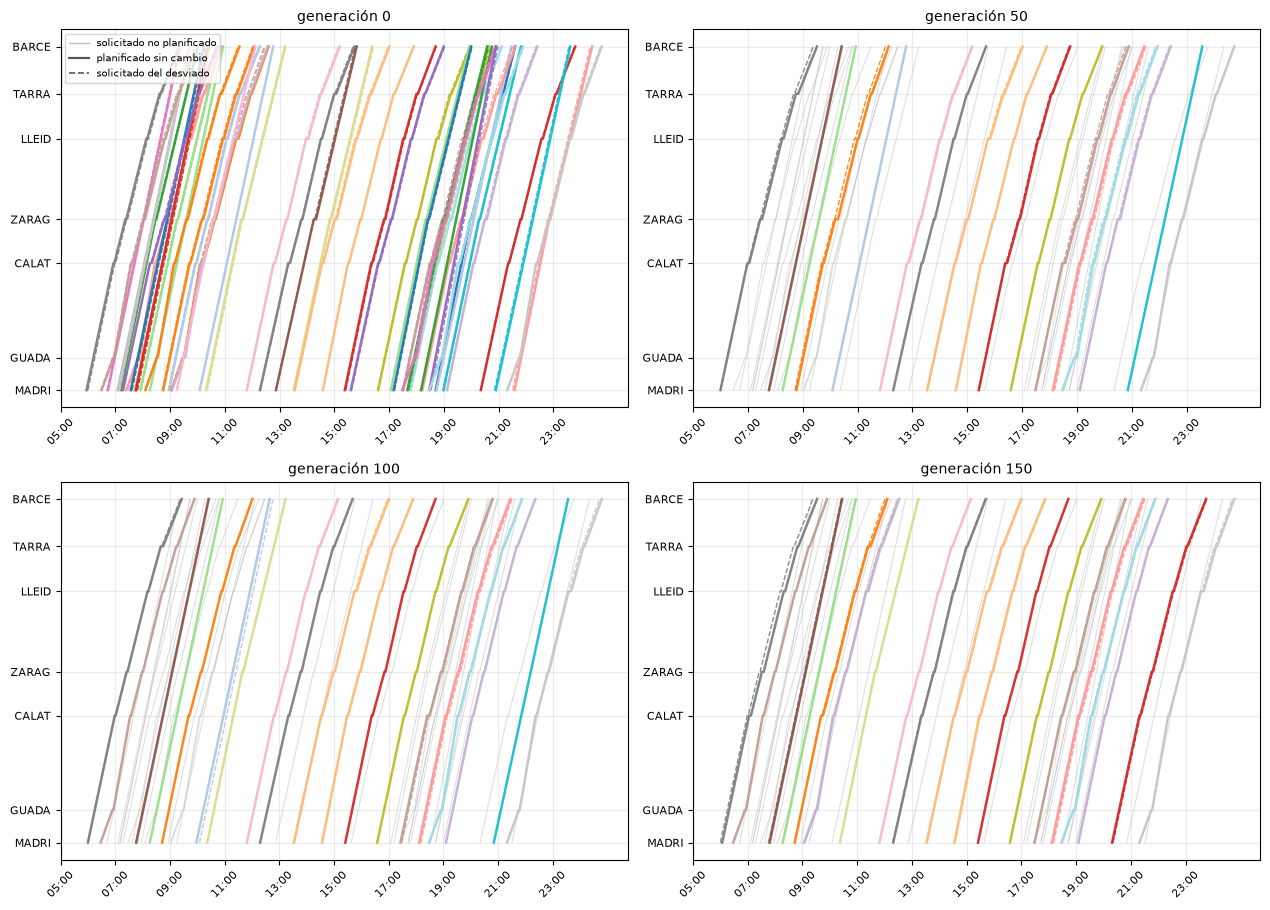

In [7]:
fig = plot_timetable_filmstrip(problem, genomes, titles)
fig.tight_layout()
plt.show()

## 4. Comparativa con el GA

Ambos solvers consumen el mismo contrato `Problem`, comparten operadores e
hiperparámetros y optimizan el mismo fitness penalizado; difieren solo en
selección y reemplazo. Presupuesto idéntico (`pop_size = 50`,
`epoch = 150`) y misma semilla: el número de evaluaciones del fitness es el
mismo (los padres no se reevalúan); NSGA-II añade el ordenamiento por
dominancia, `O((2N)²)` por generación.

In [8]:
ga = GA(problem, pop_size=50)
history_ga = ga.optimize(epoch=150, seed=42, verbose=False)


def run_row(name, solver, history):
    return {
        'solver': name,
        'fitness': round(solver.best_fitness, 2),
        'planificados': int(history['Planned'].iloc[-1]),
        'conflictos': int(history['Conflicts'].iloc[-1]),
        'tiempo (s)': round(solver.execution_time, 1),
    }


single_run = pd.DataFrame(
    [
        run_row('GA', ga, history_ga),
        run_row('NSGA-II', nsga, history_nsga),
    ]
).set_index('solver')
single_run

,fitness,planificados,conflictos,tiempo (s)
solver,,,,
GA,745.29,18,0,7.4
NSGA-II,800.03,19,0,7.7


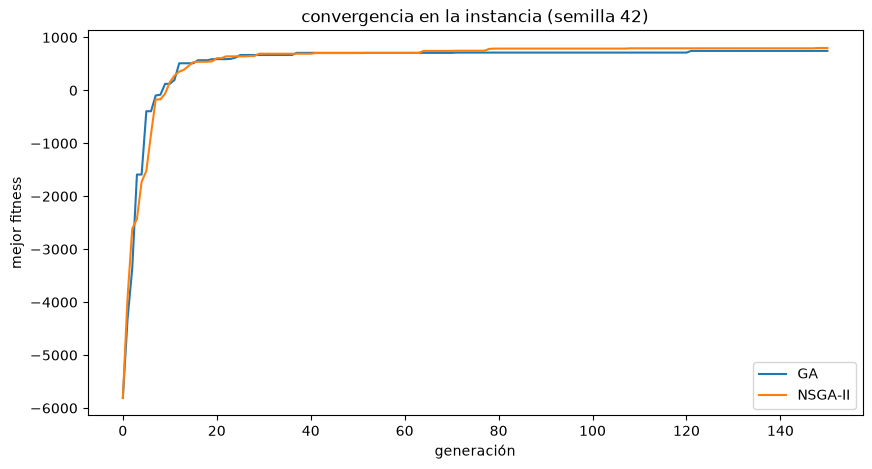

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ga.convergence, label='GA')
ax.plot(nsga.convergence, label='NSGA-II')
ax.set_xlabel('generación')
ax.set_ylabel('mejor fitness')
ax.set_title('convergencia en la instancia (semilla 42)')
ax.legend()
plt.show()

### Varias semillas

Para ir más allá de una semilla afortunada: media ± desviación típica sobre
cinco semillas con el mismo presupuesto, y la curva de convergencia media
con su banda mín–máx.

In [10]:
seeds = [7, 21, 42, 63, 84]
runs = []
convergencias = {}
for seed in seeds:
    for solver_cls in (GA, NSGA2):
        solver = solver_cls(problem, pop_size=50)
        history = solver.optimize(epoch=150, seed=seed, verbose=False)
        runs.append(
            {
                'seed': seed,
                'solver': solver_cls.__name__,
                'fitness': solver.best_fitness,
                'planificados': int(history['Planned'].iloc[-1]),
                'conflictos': int(history['Conflicts'].iloc[-1]),
                'tiempo (s)': solver.execution_time,
            }
        )
        convergencias[(solver_cls.__name__, seed)] = solver.convergence
runs_df = pd.DataFrame(runs)

summary = runs_df.groupby('solver').agg(['mean', 'std'])
summary[['fitness', 'planificados', 'conflictos', 'tiempo (s)']].round(2)

fitness        planificados       conflictos      tiempo (s)      
          mean    std         mean   std       mean  std       mean   std
solver                                                                   
GA      737.24  14.76         17.8  0.45        0.0  0.0       7.32  0.08
NSGA2   773.98  34.66         18.4  0.89        0.0  0.0       7.44  0.12

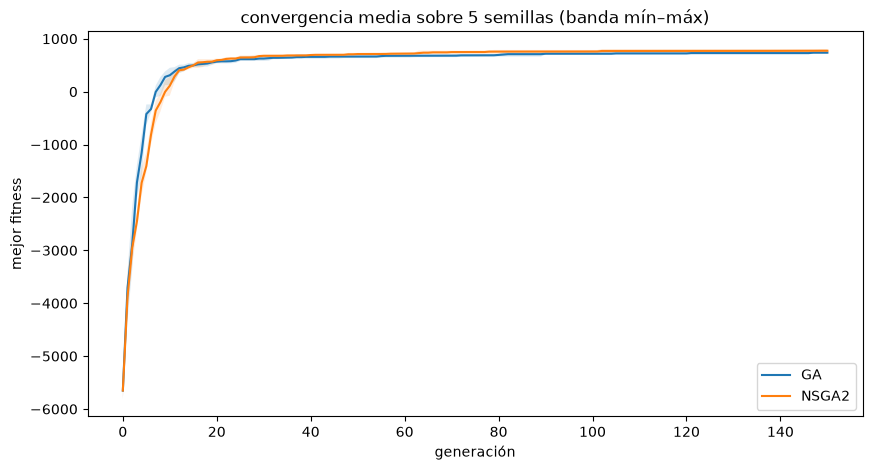

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in ('GA', 'NSGA2'):
    curves = np.stack([convergencias[(name, seed)] for seed in seeds])
    generations = np.arange(curves.shape[1])
    ax.plot(generations, curves.mean(axis=0), label=name)
    ax.fill_between(generations, curves.min(axis=0), curves.max(axis=0), alpha=0.15)
ax.set_xlabel('generación')
ax.set_ylabel('mejor fitness')
ax.set_title(f'convergencia media sobre {len(seeds)} semillas (banda mín–máx)')
ax.legend()
plt.show()

## 5. El mejor horario

Composición del mejor individuo de NSGA-II (qué servicios se planifican,
con qué desviación sobre lo solicitado y qué ingresos aportan) frente al
baseline greedy y al GA, y su diagrama espacio-tiempo final.

In [12]:
best_df = problem.schedule_frame(nsga.best_solution)
best_df.assign(
    **{
        'salida solicitada': best_df['requested_departure'].map(hhmm),
        'salida final': best_df['final_departure'].map(hhmm),
    }
).drop(columns=['requested_departure', 'final_departure'])

,service,ru,origin_delta,revenue,canon,salida solicitada,salida final
0,00004,3,-1,42.795421,42.81,13:33,13:32
1,00008,3,-4,42.687354,42.81,18:11,18:07
2,00010,1,1,43.506422,43.53,09:03,09:04
3,00011,3,2,37.059302,37.07,07:46,07:48
4,00012,1,0,42.816539,42.82,17:29,17:29
5,00015,3,1,42.802308,42.81,12:18,12:19
6,00017,3,0,42.810000,42.81,16:35,16:35
7,00026,2,1,37.025727,37.07,08:16,08:17
8,00027,1,0,42.820000,42.82,15:25,15:25
9,00030,1,-1,42.812277,42.82,19:06,19:05


In [13]:
residual = problem.conflicting_pairs(nsga.best_genome)
total_revenue = best_df['revenue'].sum()
total_canon = best_df['canon'].sum()

print(f'baseline greedy (horarios solicitados): '
      f'{greedy_n} servicios, revenue = {greedy_revenue:.2f}')
print(f'GA (mejor individuo)                  : '
      f'{history_ga["Planned"].iloc[-1]} servicios, fitness = {ga.best_fitness:.2f}')
print(f'NSGA-II (mejor individuo)             : '
      f'{len(best_df)} servicios, revenue = {total_revenue:.2f}')
print(f'penalización media sobre el canon     : '
      f'{(1 - total_revenue / total_canon) * 100:.1f} %')
print(f'conflictos residuales                 : {len(residual)} {residual}')

baseline greedy (horarios solicitados): ['00003', '00004', '00009', '00010', '00013', '00015', '00017', '00030', '00032', '00034', '00035', '00036', '00038', '00040', '00044', '00047', '00048'] servicios, revenue = 729.53
GA (mejor individuo)                  : 18 servicios, fitness = 745.29
NSGA-II (mejor individuo)             : 19 servicios, revenue = 800.03
penalización media sobre el canon     : 0.2 %
conflictos residuales                 : 0 []


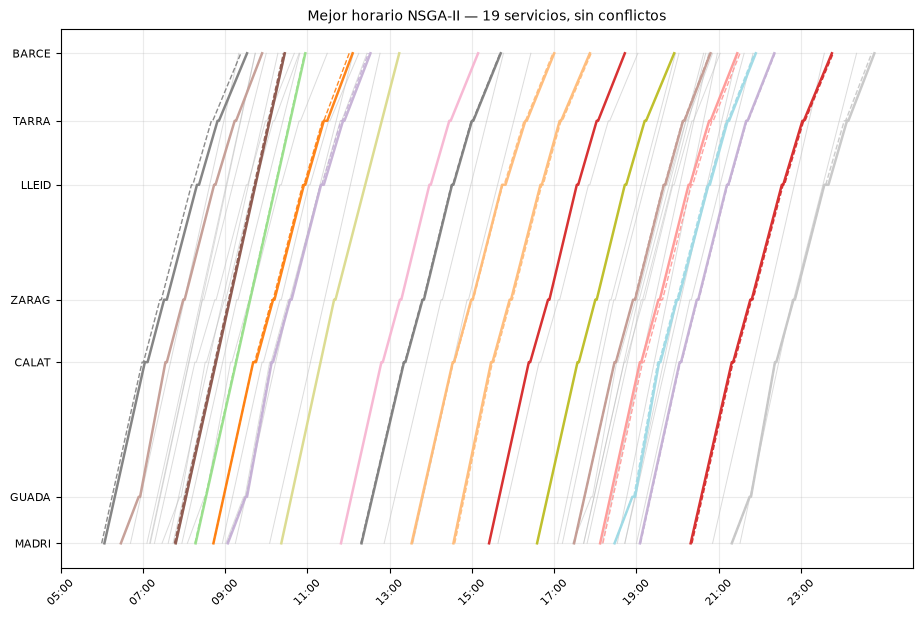

In [14]:
ax = plot_timetable(
    problem, nsga.best_genome,
    title=f'Mejor horario NSGA-II — {len(best_df)} servicios, sin conflictos',
)
plt.show()

## Notas

**Qué revisar en este cuaderno**

- La ejecución de NSGA-II sobre la misma instancia y el mismo encoding que
  el GA, sección 2, y la degeneración del frente de Pareto a un punto con
  un único objetivo.
- La **evolución de los individuos** en filmstrips con color por servicio
  consistente entre paneles, sección 3.
- La comparativa GA vs NSGA-II a igual presupuesto: semilla 42 en detalle y
  cinco semillas con media ± std, sección 4.

**Qué esperar de la comparativa**: con un solo objetivo ambos algoritmos
recorren el mismo paisaje con los mismos operadores; NSGA-II cambia la
selección (torneo apiñado) y el reemplazo (μ+λ por frentes), que con `M = 1`
equivale a un elitismo fuerte sobre la población fusionada. La maquinaria
multiobjetivo (`craft.ga.nsga2`) queda lista para optimizar, p. ej.,
`[revenue, equidad]` sin tocar la formulación.

**Siguiente fase (hecha en el paquete)**: `craft.ga.objectives` ya construye
el vector `[revenue, equidad]` (`revenue_fairness_objectives(problem,
index="jain", alpha=25)`, índices jain/gini/atkinson con la calibración del
paper fair-oriented), el solver registra `pareto_history` y `hypervolume`
calcula el área exacta del frente 2D. El flujo completo con guardado de
artefactos (frente, hipervolumen, horario *knee* y figuras en
`data/results/`) está en `scripts/run_nsga2.py`.